# The internet is infrastructure you can't see until it's missing

A-story piece: what actually predicts WA's real broadband gap? Tests two candidate "unseen" indicators against it, both at ZIP Code Tabulation Area (ZCTA) geography, both reused directly from merascope's own scored WA ZCTA grid (`data/WA/zcta/grid_scores.geojson`) — no spatial join or GEOID-prefix-matching needed, just a direct code-level join on the ZCTA.

- **Broadband gap** (the thing being predicted): Census ACS 5-year Table B28002, `pct_no_internet = B28002_013E / B28002_001E` (share of households with no internet subscription at all — the lived-reality metric, not a carrier-claimed coverage polygon). Pulled live via the Census API (key reused from `snotrac/.env`).
- **EJ score** (weak predictor, tried first): `ej_score`, higher = *less* environmental-justice burden. Correlation is real but small.
- **fiber_score** (stronger predictor, tried second on Simon's suggestion — a sharper test than the "obvious" population-density angle): distance to the nearest PeeringDB carrier hotel/colo facility, higher = closer. Correlation is ~4x the size of the EJ one, and the scatter shape itself is the finding: a funnel, not a line — proximity to backbone infrastructure is necessary but not sufficient for a low gap.

In [1]:
import json
from pathlib import Path

import numpy as np
import requests
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from scipy import stats

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
CENSUS_CACHE = DATA_DIR / "acs_b28002_zcta_national.json"
GRID_PATH = Path("../../merascope/data/WA/zcta/grid_scores.geojson")


def load_census_api_key():
    env_path = Path("../../snotrac/.env")
    for line in env_path.read_text().splitlines():
        if line.startswith("CENSUS_API_KEY="):
            return line.split("=", 1)[1].strip()
    raise RuntimeError("CENSUS_API_KEY not found in snotrac/.env")


API_KEY = load_census_api_key()

In [2]:
# ACS Table B28002 has no state-level geography hierarchy for ZCTAs (confirmed live --
# a state-filtered query 400s with "unknown/unsupported geography hierarchy"), so this
# pulls all ~33.7k national ZCTAs in one call and filters to WA locally against merascope's
# own grid in the next cell. Cached after first pull.
if CENSUS_CACHE.exists():
    rows = json.loads(CENSUS_CACHE.read_text())
else:
    resp = requests.get(
        "https://api.census.gov/data/2023/acs/acs5",
        params={
            "get": "NAME,B28002_001E,B28002_013E",
            "for": "zip code tabulation area:*",
            "key": API_KEY,
        },
        timeout=60,
    )
    resp.raise_for_status()
    rows = resp.json()
    CENSUS_CACHE.write_text(json.dumps(rows))

header, *data_rows = rows
census = {
    r[3]: {"total_hh": int(r[1]), "no_internet_hh": int(r[2])}
    for r in data_rows
    if int(r[1]) > 0
}
print(f"loaded {len(census)} national ZCTAs from ACS B28002 (total households > 0)")

loaded 32828 national ZCTAs from ACS B28002 (total households > 0)


In [3]:
grid = json.loads(GRID_PATH.read_text())["features"]
print(f"loaded {len(grid)} WA ZCTAs from merascope's scored grid")

sites = []
for feat in grid:
    z = feat["properties"]["zcta"]
    c = census.get(z)
    if c is None:
        continue
    sites.append({
        "zcta": z,
        "ej_score": feat["properties"]["ej_score"],
        "fiber_score": feat["properties"]["fiber_score"],
        "fac_dist_m": feat["properties"]["fac_dist_m"],
        "pct_no_internet": 100 * c["no_internet_hh"] / c["total_hh"],
        "geometry": feat["geometry"],
    })

join_rate = len(sites) / len(grid)
print(f"joined {len(sites)}/{len(grid)} WA ZCTAs ({100*join_rate:.1f}%)")

loaded 605 WA ZCTAs from merascope's scored grid
joined 585/605 WA ZCTAs (96.7%)


In [4]:
# Self-check before any claim: bad join or wrong variable codes would silently
# produce a plausible-looking but meaningless chart. feedback_verify_before_asserting.
assert join_rate > 0.90, f"join rate {join_rate:.1%} too low -- check zcta code formats match"

pct_vals = np.array([s["pct_no_internet"] for s in sites])
assert 1 < pct_vals.mean() < 40, f"mean no-internet rate {pct_vals.mean():.1f}% outside plausible range -- check B28002 variable codes"

print(f"WA mean no-internet-subscription rate: {pct_vals.mean():.1f}% (n={len(sites)} ZCTAs)")
print(f"range: {pct_vals.min():.1f}% - {pct_vals.max():.1f}%")

ej_vals = np.array([s["ej_score"] for s in sites])
rho, p = stats.spearmanr(ej_vals, pct_vals)
print(f"Spearman rho (ej_score vs pct_no_internet): {rho:.3f}, p={p:.4g}, n={len(sites)}")

worst_ej = min(sites, key=lambda s: s["ej_score"])
worst_bb = max(sites, key=lambda s: s["pct_no_internet"])
print(f"worst EJ score:  zcta {worst_ej['zcta']}  ej={worst_ej['ej_score']:.3f}  no_internet={worst_ej['pct_no_internet']:.1f}%")
print(f"worst broadband: zcta {worst_bb['zcta']}  ej={worst_bb['ej_score']:.3f}  no_internet={worst_bb['pct_no_internet']:.1f}%")

# fiber_score direction check -- confirm "higher = better" (closer to a facility)
# before trusting any correlation sign built on top of it.
fiber_vals = np.array([s["fiber_score"] for s in sites])
fac_dist_vals = np.array([s["fac_dist_m"] for s in sites])
dir_check, _ = stats.spearmanr(fiber_vals, fac_dist_vals)
assert dir_check < -0.9, f"fiber_score doesn't track fac_dist_m as expected (rho={dir_check:.3f}) -- check score direction"
print(f"\nfiber_score direction check: rho vs fac_dist_m = {dir_check:.3f} (confirms higher fiber_score = closer to a carrier hotel/colo facility)")

rho_fiber, p_fiber = stats.spearmanr(fiber_vals, pct_vals)
print(f"Spearman rho (fiber_score vs pct_no_internet): {rho_fiber:.3f}, p={p_fiber:.4g}, n={len(sites)}")

worst_fiber = min(sites, key=lambda s: s["fiber_score"])
print(f"worst fiber access: zcta {worst_fiber['zcta']}  fiber_score={worst_fiber['fiber_score']:.3f}  fac_dist_m={worst_fiber['fac_dist_m']:.0f}  no_internet={worst_fiber['pct_no_internet']:.1f}%")

WA mean no-internet-subscription rate: 7.5% (n=585 ZCTAs)
range: 0.0% - 71.4%
Spearman rho (ej_score vs pct_no_internet): -0.092, p=0.02594, n=585
worst EJ score:  zcta 98350  ej=0.000  no_internet=27.2%
worst broadband: zcta 99034  ej=0.592  no_internet=71.4%

fiber_score direction check: rho vs fac_dist_m = -1.000 (confirms higher fiber_score = closer to a carrier hotel/colo facility)
Spearman rho (fiber_score vs pct_no_internet): -0.367, p=4.135e-20, n=585
worst fiber access: zcta 98862  fiber_score=0.000  fac_dist_m=151289  no_internet=1.0%


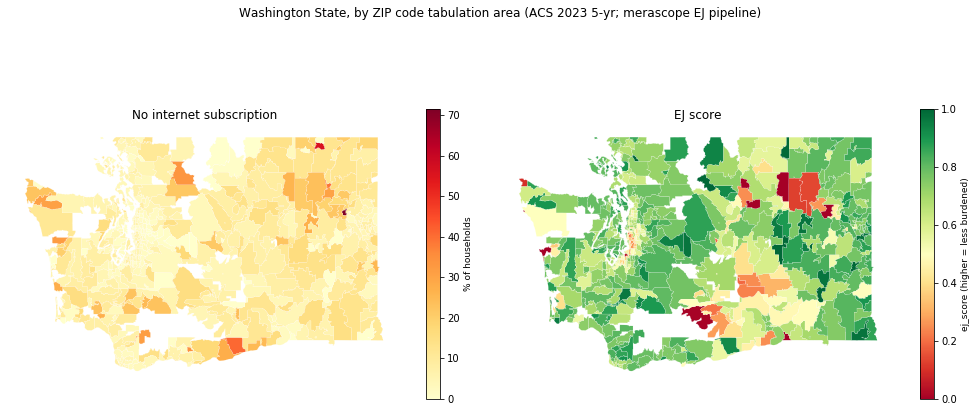

In [5]:
def rings(geometry):
    """Yield exterior-ring (lon, lat) arrays for a Polygon or MultiPolygon feature."""
    coords = geometry["coordinates"]
    polys = [coords] if geometry["type"] == "Polygon" else coords
    for poly in polys:
        yield np.array(poly[0])


all_lats = np.concatenate([ring[:, 1] for s in sites for ring in rings(s["geometry"])])
LAT_ASPECT = 1 / np.cos(np.radians(all_lats.mean()))


def plot_choropleth(ax, field, cmap, vmin, vmax, title, cbar_label):
    patches, values = [], []
    for s in sites:
        for ring in rings(s["geometry"]):
            patches.append(Polygon(ring, closed=True))
            values.append(s[field])
    coll = PatchCollection(patches, cmap=cmap)
    coll.set_array(np.array(values))
    coll.set_clim(vmin, vmax)
    coll.set_edgecolor("white")
    coll.set_linewidth(0.15)
    ax.add_collection(coll)
    ax.autoscale_view()
    ax.set_aspect(LAT_ASPECT)
    ax.axis("off")
    ax.set_title(title, fontsize=12)
    cbar = plt.colorbar(coll, ax=ax, shrink=0.6)
    cbar.set_label(cbar_label, fontsize=9)


fig, axes = plt.subplots(1, 2, figsize=(14, 7))
plot_choropleth(axes[0], "pct_no_internet", "YlOrRd", 0, pct_vals.max(),
                 "No internet subscription", "% of households")
plot_choropleth(axes[1], "ej_score", "RdYlGn", 0, 1,
                 "EJ score", "ej_score (higher = less burdened)")
fig.suptitle("Washington State, by ZIP code tabulation area (ACS 2023 5-yr; merascope EJ pipeline)",
             fontsize=12, y=0.99)
fig.tight_layout()
fig.savefig("broadband_ej_overlay_maps.png", dpi=150, bbox_inches="tight")
plt.show()

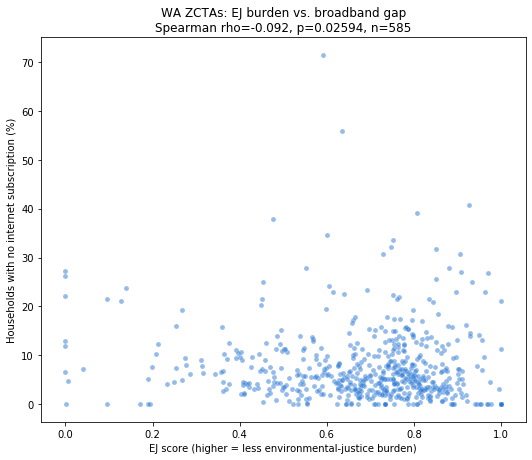

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.scatter(ej_vals, pct_vals, s=25, alpha=0.5, color="#2a78d6", edgecolor="white", linewidth=0.3)
ax.set_xlabel("EJ score (higher = less environmental-justice burden)")
ax.set_ylabel("Households with no internet subscription (%)")
ax.set_title(f"WA ZCTAs: EJ burden vs. broadband gap\nSpearman rho={rho:.3f}, p={p:.4g}, n={len(sites)}")
fig.tight_layout()
fig.savefig("broadband_ej_overlay_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

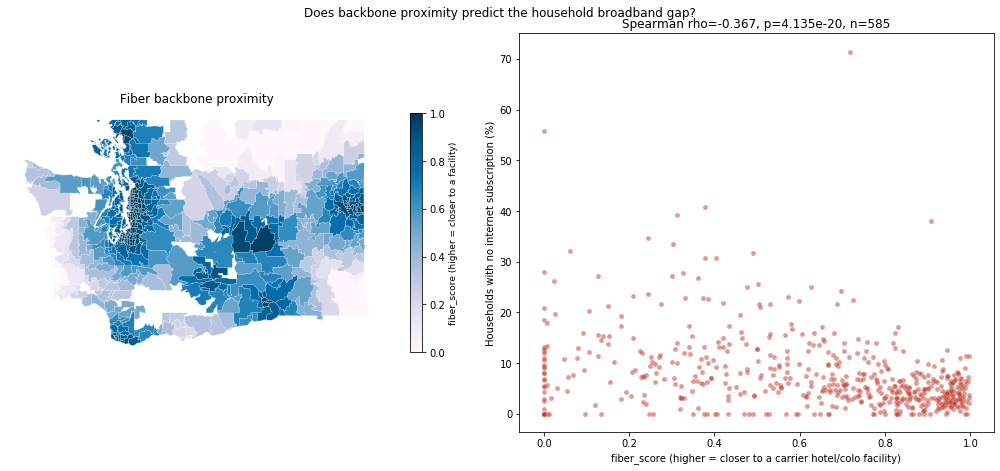

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
plot_choropleth(axes[0], "fiber_score", "PuBu", 0, 1,
                 "Fiber backbone proximity", "fiber_score (higher = closer to a facility)")
axes[1].scatter(fiber_vals, pct_vals, s=25, alpha=0.5, color="#c0392b", edgecolor="white", linewidth=0.3)
axes[1].set_xlabel("fiber_score (higher = closer to a carrier hotel/colo facility)")
axes[1].set_ylabel("Households with no internet subscription (%)")
axes[1].set_title(f"Spearman rho={rho_fiber:.3f}, p={p_fiber:.4g}, n={len(sites)}")
fig.suptitle("Does backbone proximity predict the household broadband gap?", fontsize=12, y=1.0)
fig.tight_layout()
fig.savefig("broadband_fiber_overlay.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary

- **EJ score**: weak. rho=-0.092, p=0.026, n=585.
- **fiber_score**: much stronger. rho=-0.367, p=4.1e-20, n=585 — and shaped like a funnel, not a line: close to a facility, the no-internet gap is capped low (0-10%); far from one, it spans the full 0-70%+ range. Proximity is necessary but not sufficient.
- **Named anomalies, not smoothed over**: Tumtum (99034, 71.4% no-internet) isn't explained by EJ burden (middling, 0.592) *or* fiber distance (fiber_score~0.7, reasonably well-positioned) — stays a real unexplained outlier. Winthrop (98862, affluent North Cascades tourist town) is the single farthest ZCTA from any facility in the state (94 mi) yet sits at just 1.0% no-internet — some other factor (money, satellite, local investment) is covering for the distance there.

Caption not yet drafted. Likely leads with the fiber funnel shape + the Winthrop counter-example over the weaker EJ correlation.

## Fiber backbone vs. internet access, side by side

Same two signals, positive-framed and paired directly: `fiber_score` (backbone proximity) on the left, `access_score = 1 - pct_no_internet` (share of households actually connected) on the right.

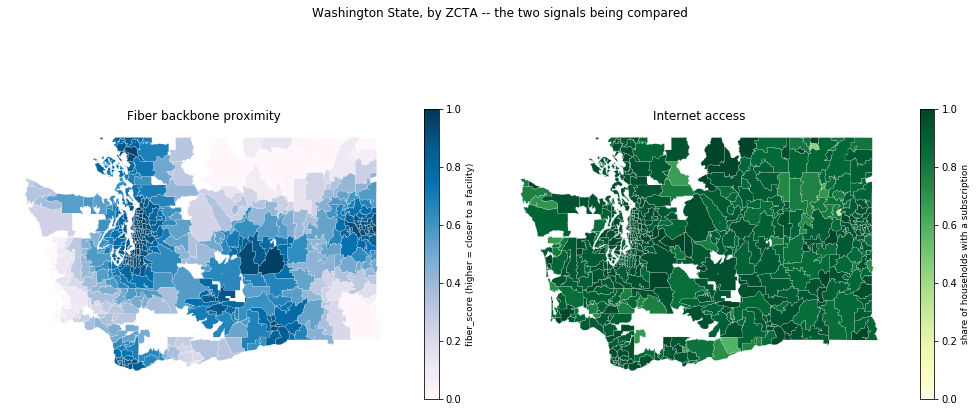

In [8]:
access_vals = 1 - pct_vals / 100
for s, av in zip(sites, access_vals):
    s["access_score"] = av

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
plot_choropleth(axes[0], "fiber_score", "PuBu", 0, 1,
                 "Fiber backbone proximity", "fiber_score (higher = closer to a facility)")
plot_choropleth(axes[1], "access_score", "YlGn", 0, 1,
                 "Internet access", "share of households with a subscription")
fig.suptitle("Washington State, by ZCTA -- the two signals being compared", fontsize=12, y=0.99)
fig.tight_layout()
fig.savefig("broadband_fiber_access_pair.png", dpi=150, bbox_inches="tight")
plt.show()

## The gap, explicit

Before the combined view: the single-number version of the same question, `gap = access_rank - fiber_rank`. Blue = fiber proximity exceeds household access (infrastructure nearby, households not connected). Red = access exceeds fiber proximity (connected some other way — satellite, cable, a provider not in the PeeringDB facility list). Gray = the two roughly agree.

## Interference map — same color scale, two independent stripes

Simpler than computing a derived agreement/disagreement axis: one shared diverging colormap, applied independently to each variable's own percentile rank — `fiber_score`'s rank drives one stripe, `access_score`'s rank drives the other. No math needed to read it; the pairing itself is the readout:

- **Same color on both stripes** = the two signals agree (both blue = confirmed-bad, both red = confirmed-good, both gray = both average).
- **Contrasting stripes (one red, one blue)** = the two signals disagree — a real surprise, whichever direction.

Rank-normalized for the same reason as before: `access_score` is heavily right-skewed (state mean no-internet is only 7.5%), so raw values would put nearly every ZCTA's access stripe at the same "high" end regardless of true relative position. Midpoint is light gray, not white — pure white in the first version was indistinguishable from the map's actual no-data gaps.

In [9]:
from scipy.stats import rankdata
from matplotlib.colors import LinearSegmentedColormap, Normalize

# Same premise as before: access_score is heavily right-skewed, so raw values would
# put nearly every ZCTA's access stripe at the same "high" end regardless of true
# relative position. Percentile rank puts both variables on the same 0-1 scale before
# the shared colormap sees them.
assert access_vals.std() < fiber_vals.std() / 2, (
    f"access_score (std={access_vals.std():.3f}) isn't much more compressed than "
    f"fiber_score (std={fiber_vals.std():.3f}) -- rank-normalizing may not be needed"
)

f_rank = rankdata(fiber_vals) / len(fiber_vals)
a_rank = rankdata(access_vals) / len(access_vals)

# Light gray midpoint instead of coolwarm's pure white -- pure white read as
# indistinguishable from the map's actual no-data gaps (Simon's catch).
SHARED_CMAP = LinearSegmentedColormap.from_list("blue_gray_red", ["#3b4cc0", "#d9d9d9", "#b40426"])
fiber_colors = SHARED_CMAP(Normalize(0, 1)(f_rank))
access_colors = SHARED_CMAP(Normalize(0, 1)(a_rank))

# Self-check: Winthrop (98862) has the lowest fiber_score in the state and a
# near-best access rate -- its two stripes should clash (one near-blue, one
# near-red), the sharpest disagreement case found so far.
winthrop_idx = [s["zcta"] for s in sites].index("98862")
print(f"Winthrop (98862): fiber_rank={f_rank[winthrop_idx]:.3f}, access_rank={a_rank[winthrop_idx]:.3f}")
assert f_rank[winthrop_idx] < 0.05 and a_rank[winthrop_idx] > 0.85, \
    "Winthrop's ranks don't read as an extreme disagreement case -- check rank direction"

Winthrop (98862): fiber_rank=0.027, access_rank=0.899


gap range: -0.798 - 0.933
Winthrop (98862) gap: 0.872 (expect near the maximum -- access far exceeds fiber proximity)


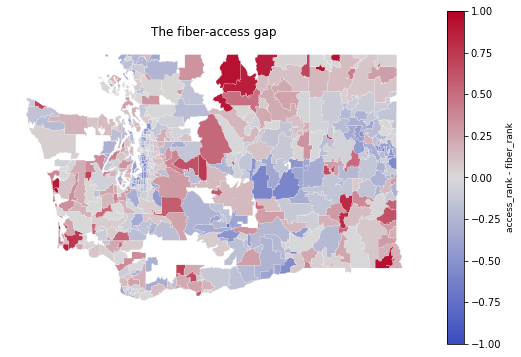

In [10]:
gap = a_rank - f_rank
for s, g in zip(sites, gap):
    s["gap"] = g

print(f"gap range: {gap.min():.3f} - {gap.max():.3f}")
print(f"Winthrop (98862) gap: {sites[winthrop_idx]['gap']:.3f} (expect near the maximum -- access far exceeds fiber proximity)")
assert sites[winthrop_idx]["gap"] > np.percentile(gap, 95), "Winthrop isn't reading as a high-gap outlier -- check sign"

fig, ax = plt.subplots(figsize=(7.5, 8))
coll = plot_choropleth(ax, "gap", SHARED_CMAP, -1, 1,
                        "The fiber-access gap", "access_rank - fiber_rank")
fig.tight_layout()
fig.savefig("broadband_fiber_access_gap.png", dpi=150, bbox_inches="tight")
plt.show()

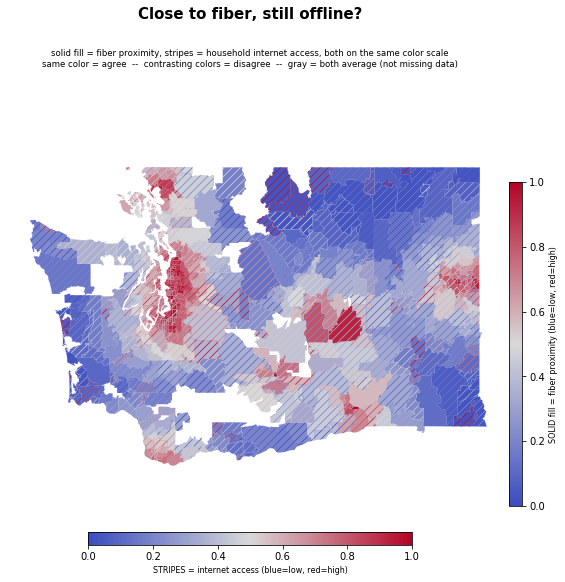

In [11]:
patches, patch_fiber = [], []
hatch_polys = []
for s, fc, ac in zip(sites, fiber_colors, access_colors):
    for ring in rings(s["geometry"]):
        patches.append(Polygon(ring, closed=True))
        patch_fiber.append(fc)
        hatch_polys.append((ring, ac))

# Sparser, thinner, softer stripes than the first pass -- a single '/' instead of
# '//' (fewer lines), lower linewidth, and reduced alpha on the stripe color so the
# underlying fill reads first and the overlay reads second, not both at once.
plt.rcParams["hatch.linewidth"] = 1
STRIPE_ALPHA = 0.8

fig, ax = plt.subplots(figsize=(9, 9))
fig.subplots_adjust(top=0.86)  # room for the title + subtitle below it, no overlap
fill = PatchCollection(patches, facecolor=patch_fiber, edgecolor="none")
ax.add_collection(fill)
# Same per-patch-hatch-color limitation as before (PatchCollection hatch ignores a
# per-patch edgecolor array in this matplotlib version) -- individual Patch objects.
for ring, ac in hatch_polys:
    ax.add_patch(Polygon(ring, closed=True, facecolor="none", hatch="///",
                          edgecolor=(ac[0], ac[1], ac[2], STRIPE_ALPHA), linewidth=0.15))

ax.autoscale_view()
ax.set_aspect(LAT_ASPECT)
ax.axis("off")

fig.suptitle("Close to fiber, still offline?", fontsize=15, fontweight="bold", y=0.97)
fig.text(0.5, 0.905,
         "solid fill = fiber proximity, stripes = household internet access, both on the same color scale\n"
         "same color = agree  --  contrasting colors = disagree  --  gray = both average (not missing data)",
         ha="center", va="top", fontsize=8.5)

# Which visual channel is which was genuinely ambiguous without this -- Simon asked
# "are stripes internet access or fiber score?" the first time he saw it.
cax_v = fig.add_axes([0.90, 0.2, 0.02, 0.5])
cb_v = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(0, 1), cmap=SHARED_CMAP), cax=cax_v)
cb_v.set_label("SOLID fill = fiber proximity (blue=low, red=high)", fontsize=8)

cax_h = fig.add_axes([0.25, 0.14, 0.5, 0.02])
cb_h = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(0, 1), cmap=SHARED_CMAP), cax=cax_h, orientation="horizontal")
cb_h.set_label("STRIPES = internet access (blue=low, red=high)", fontsize=8)

fig.savefig("broadband_interference_map.png", dpi=150, bbox_inches="tight")
plt.show()

## Let a model find the real predictor

Rather than keep hand-picking one indicator at a time (EJ score, then fiber_score): pull every one of merascope's ~22 precomputed indicator scores as candidate features, add one new engineered feature testing Simon's transmission-line hypothesis (proximity to the grid itself, not just to a carrier facility — real WA transmission-line geometry, OSM-sourced, already sitting in merascope's data), and let a random forest rank them by actual predictive importance against `pct_no_internet`. Cross-validated R² reported before trusting any importance ranking — a model that doesn't actually predict anything would make the ranking meaningless.

In [12]:
# Every one of merascope's own precomputed indicator scores (not raw values, not the
# nationally-renormalized "_nat" duplicates) as ML candidate features.
SCORE_FIELDS = sorted(
    k for k in grid[0]["properties"] if k.endswith("_score") and "_nat" not in k
)
print(f"{len(SCORE_FIELDS)} candidate indicator scores from merascope's pipeline:")
print(SCORE_FIELDS)

zcta_to_props = {f["properties"]["zcta"]: f["properties"] for f in grid}
for s in sites:
    props = zcta_to_props[s["zcta"]]
    for field in SCORE_FIELDS:
        s[field] = props[field]

23 candidate indicator scores from merascope's pipeline:
['air_quality_score', 'aquifer_score', 'contamination_score', 'ej_score', 'fiber_score', 'flatness_score', 'flood_score', 'geothermal_score', 'grid_capacity_score', 'ksat_score', 'pop_exposure_score', 'protected_score', 'rcra_score', 'seismic_score', 'slope_score', 'soil_profile_score', 'soil_score', 'substation_score', 'superfund_score', 'tx_score', 'water_score', 'water_stress_score', 'waterway_score']


In [13]:
from shapely.geometry import shape
from shapely.strtree import STRtree

TX_PATH = Path("../../merascope/data/raw/transmission_wa.geojson")
tx_geo = json.loads(TX_PATH.read_text())
tx_lines = [shape(f["geometry"]) for f in tx_geo["features"]]
print(f"loaded {len(tx_lines)} WA transmission line segments (OSM, merascope's power-grid overlay)")

tree = STRtree(tx_lines)
tx_dist_deg = []
for s in sites:
    centroid = shape(s["geometry"]).centroid
    result = tree.nearest(centroid)
    # shapely 2.x returns an index; older shapely returns the geometry itself
    nearest_line = tx_lines[result] if isinstance(result, (int, np.integer)) else result
    tx_dist_deg.append(centroid.distance(nearest_line))

# Degrees -> meters is a rough conversion at WA's latitude (not a precise geodesic),
# fine for a ranking feature, not for a claimed physical distance.
tx_dist_m = np.array(tx_dist_deg) * 111_000
tx_proximity_score = 1 - (tx_dist_m - tx_dist_m.min()) / (tx_dist_m.max() - tx_dist_m.min())
for s, v in zip(sites, tx_proximity_score):
    s["tx_proximity_score"] = v

print(f"transmission-line distance: {tx_dist_m.min():.0f}m - {tx_dist_m.max():.0f}m")
print(f"Winthrop (98862) tx_proximity_score: {sites[winthrop_idx]['tx_proximity_score']:.3f}")

loaded 6127 WA transmission line segments (OSM, merascope's power-grid overlay)
transmission-line distance: 15m - 52792m
Winthrop (98862) tx_proximity_score: 0.773


In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

FEATURES = SCORE_FIELDS + ["tx_proximity_score"]
X = np.array([[s[f] for f in FEATURES] for s in sites])
y = pct_vals  # predicting the real broadband gap directly

model = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0)
cv_r2 = cross_val_score(model, X, y, cv=5, scoring="r2")
print(f"5-fold CV R^2: {cv_r2.mean():.3f} +/- {cv_r2.std():.3f}")
# Self-check: a model that doesn't actually predict anything makes the importance
# ranking below meaningless -- don't trust it past this point if R^2 is near zero.
assert cv_r2.mean() > 0.15, f"model barely predicts pct_no_internet (R^2={cv_r2.mean():.3f}) -- importances below aren't trustworthy"

model.fit(X, y)
importances = sorted(zip(FEATURES, model.feature_importances_), key=lambda t: -t[1])
print("\nfeature importances, ranked:")
for name, imp in importances:
    marker = "  <-- Simon's transmission-line hypothesis" if name == "tx_proximity_score" else ""
    print(f"  {name:25s} {imp:.4f}{marker}")

top_feature = importances[0][0]
fiber_rank = [name for name, _ in importances].index("fiber_score") + 1
tx_rank = [name for name, _ in importances].index("tx_proximity_score") + 1
print(f"\ntop feature: {top_feature}")
print(f"fiber_score ranks #{fiber_rank} of {len(FEATURES)}")
print(f"tx_proximity_score ranks #{tx_rank} of {len(FEATURES)}")

5-fold CV R^2: 0.183 +/- 0.102

feature importances, ranked:
  pop_exposure_score        0.3259
  ej_score                  0.0991
  substation_score          0.0566
  superfund_score           0.0486
  fiber_score               0.0450
  rcra_score                0.0418
  aquifer_score             0.0407
  geothermal_score          0.0344
  seismic_score             0.0332
  ksat_score                0.0318
  contamination_score       0.0312
  water_score               0.0305
  soil_profile_score        0.0285
  waterway_score            0.0266
  tx_proximity_score        0.0256  <-- Simon's transmission-line hypothesis
  soil_score                0.0250
  tx_score                  0.0241
  slope_score               0.0195
  flatness_score            0.0175
  water_stress_score        0.0134
  protected_score           0.0007
  air_quality_score         0.0003
  flood_score               0.0000
  grid_capacity_score       0.0000

top feature: pop_exposure_score
fiber_score ranks #5 of 

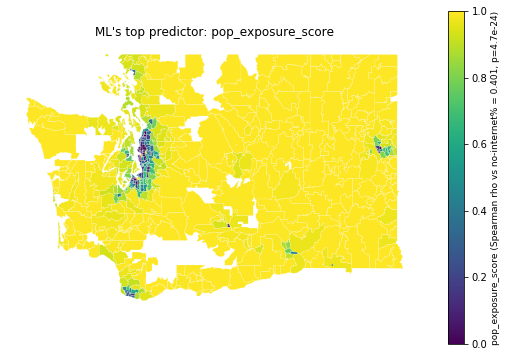

In [15]:
top_vals = np.array([s[top_feature] for s in sites])
rho_top, p_top = stats.spearmanr(top_vals, pct_vals)

fig, ax = plt.subplots(figsize=(7.5, 8))
plot_choropleth(ax, top_feature, "viridis", float(top_vals.min()), float(top_vals.max()),
                 f"ML's top predictor: {top_feature}",
                 f"{top_feature} (Spearman rho vs no-internet% = {rho_top:.3f}, p={p_top:.2g})")
fig.tight_layout()
fig.savefig("broadband_ml_top_feature.png", dpi=150, bbox_inches="tight")
plt.show()

## Reliability check — is any of this actually signal?

Simon's pushback, verbatim: "we're just putting colors on a map and saying they encode information. It's not, it's just noise." Fair challenge given the CV R² above (0.183 ± 0.102 — most of the variance is unexplained by everything tested). One thing never checked until now: B28002 is a 5-year ACS **estimate**, not a census count — every value has a published margin of error, and for a rare category like "no internet" in a small-population ZCTA that margin can swallow the entire signal being color-coded. Pulling `B28002_001M`/`B28002_013M` (the MOE companions to the estimates already used) to check whether the specific named anomalies survive, or whether they're statistically indistinguishable from the state average.

In [16]:
MOE_CACHE = DATA_DIR / "acs_b28002_moe_zcta_national.json"
if MOE_CACHE.exists():
    moe_rows = json.loads(MOE_CACHE.read_text())
else:
    resp = requests.get(
        "https://api.census.gov/data/2023/acs/acs5",
        params={
            "get": "NAME,B28002_001E,B28002_001M,B28002_013E,B28002_013M",
            "for": "zip code tabulation area:*",
            "key": API_KEY,
        },
        timeout=60,
    )
    resp.raise_for_status()
    moe_rows = resp.json()
    MOE_CACHE.write_text(json.dumps(moe_rows))

moe = {
    r[5]: {"total_hh": int(r[1]), "total_moe": int(r[2]), "no_internet_hh": int(r[3]), "no_internet_moe": int(r[4])}
    for r in moe_rows[1:]
}
for s in sites:
    s.update(moe[s["zcta"]])

# Census Bureau's own reliability convention: coefficient of variation on the 90%
# MOE, converted to a standard error first. CV > 30% = "use with caution", the
# Bureau's own published threshold, not one invented here.
def cv_pct(m):
    est = m["no_internet_hh"]
    return None if est == 0 else (m["no_internet_moe"] / 1.645) / est * 100

cvs = [cv_pct(s) for s in sites]
cvs_valid = [c for c in cvs if c is not None]
zero_est = sum(1 for c in cvs if c is None)
unreliable_30 = sum(1 for c in cvs_valid if c > 30)
print(f"zero-estimate ZCTAs (no_internet_hh=0, CV undefined -- these are the ones plotted as a clean 0.0%): {zero_est}/{len(sites)}")
print(f"of the remaining {len(cvs_valid)}: CV>30% (Census's own 'use with caution' threshold): {unreliable_30} ({100*unreliable_30/len(cvs_valid):.1f}%)")
print(f"median CV among nonzero estimates: {sorted(cvs_valid)[len(cvs_valid)//2]:.1f}%")

print("\nnamed anomalies, with their real margins of error:")
for z, label in [("98862", "Winthrop"), ("99034", "Tumtum"), ("98350", "La Push")]:
    m = moe[z]
    pct = 100 * m["no_internet_hh"] / m["total_hh"]
    pct_moe = 100 * m["no_internet_moe"] / m["total_hh"]
    print(f"  {label:10s} ({z}): {pct:.1f}% no-internet, 90% MOE +/- {pct_moe:.1f} points "
          f"(estimate itself: {m['no_internet_hh']} +/- {m['no_internet_moe']} households, n={m['total_hh']} total)")

zero-estimate ZCTAs (no_internet_hh=0, CV undefined -- these are the ones plotted as a clean 0.0%): 47/585
of the remaining 538: CV>30% (Census's own 'use with caution' threshold): 312 (58.0%)
median CV among nonzero estimates: 33.5%

named anomalies, with their real margins of error:
  Winthrop   (98862): 1.0% no-internet, 90% MOE +/- 1.7 points (estimate itself: 14 +/- 24 households, n=1387 total)
  Tumtum     (99034): 71.4% no-internet, 90% MOE +/- 89.0 points (estimate itself: 65 +/- 81 households, n=91 total)
  La Push    (98350): 27.2% no-internet, 90% MOE +/- 16.3 points (estimate itself: 25 +/- 15 households, n=92 total)
